# 9. Supplementary -- weak claims

- Analyses kept for reference whose claim did not hold up as evidence for NM. Not part of the main narrative.
- Each section states why the claim is weak and the highest claim level it can still carry.

## 1. Severity ladder (moved from notebook 8, 2026-11-13)

- **Why weak**: the same ladder selection run on logCPM also puts liver as the top panel (164 genes, 35 liver, OR 8.6),
  so the liver ladder is not NM-specific. Without selection, the whole liver panel (390 genes) trends weakly with
  stage on both scales (Z rho 0.27, logCPM rho 0.17, both n.s.).
- **Claim level kept**: NM deviations are consistent with clinical severity. Not a reason NM is needed.


In [ ]:
import os
import pickle
import sys
from pathlib import Path

import h5py
import matplotlib.colors as mcolors
import matplotlib.patheffects as pe
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import norm

os.environ["NM_PIPELINE"] = "p0"
parent_dir = str(Path.cwd().parents[1])
if parent_dir not in sys.path:
    sys.path.insert(0, parent_dir)
from viz_style import FS_ANNOT_LG, FS_ANNOT_SM, apply_style
apply_style()

import MixedEffectsModeling.config as config
from MixedEffectsModeling.core.calibration import bh_fdr_reject
from MixedEffectsModeling.notebookscripts import hpa_panels
%matplotlib inline

CPAL = {'grey': '#A2A2A2', 'dgrey': '#4D4D4D', 'blue': '#489ACA', 'green': '#009E73',
        'pink': '#CC79A7', 'red': '#B2182B', 'dred': '#67001F', 'purple': '#6A3D9A',
        'navy': '#2166AC', 'orange': '#E08214', 'teal': '#35978F'}
CPAL_L = {'grey': '#DDDDDD', 'dgrey': '#9A9A9A', 'blue': '#A6CEE3', 'green': '#A1D9C3',
          'pink': '#F2C6DE', 'red': '#F4A582', 'purple': '#CBB4DE', 'navy': '#92B6D5',
          'orange': '#FDD9A0', 'teal': '#A8D5D0'}
CPAL_CAT = [CPAL['red'], CPAL['blue'], CPAL['green'], CPAL['purple'], CPAL['orange'], CPAL['pink'],
            CPAL['navy'], CPAL['teal'], CPAL_L['red'], CPAL_L['blue'], CPAL_L['green'],
            CPAL_L['purple'], CPAL_L['orange'], CPAL_L['pink'], CPAL_L['navy'], CPAL['grey']]
BLK_RAMP8 = ['#E4E4E4', CPAL['grey'], CPAL_L['orange'], CPAL_L['green'],
             CPAL_L['purple'], '#A78BC4', '#7E5AA8', '#4A2A75']
DIV_CMAP = 'RdBu_r'

MOORE_BATCHES = ['Moore et al._Batch_1', 'Moore et al._Batch_2', 'Moore et al._Batch_3']
NEOPLASTIC = ['IPMN', 'Islet Cell Tumor', 'PDAC']
FDR_Q = 0.05
MIN_HIT_READS = 10
PANEL_CAP = 200
SEED = 0

OUT = config.WEAK_CLAIM_DIR
FIG = config.WEAK_CLAIM_FIG_DIR
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)


In [ ]:
ZD = config.ZSCORES_DIR
dm = pd.read_csv(ZD / 'sample_meta.csv')
hm = pd.read_csv(ZD / 'hc_meta.csv')
dk = dm['ood_keep'].values.astype(bool)
src = dict(Z_dis=np.load(ZD / 'Z_disease_shash.npy')[dk], dis=dm.loc[dk, 'sample'].values,
           dis_batch=dm.loc[dk, 'batch'].values)
genes = np.array(pickle.load(open(ZD / 'gene_names.pkl', 'rb')))
Z_hc_all, hc_all, hc_batch = np.load(ZD / 'Z_hc_shash.npy'), hm['sample'].values, hm['batch'].values

dec = lambda a: np.array([x.decode('utf-8', 'replace') if isinstance(x, bytes) else str(x) for x in a])

def obs_cat(h, c):
    o = h['obs'][c]
    return (pd.Categorical.from_codes(o['codes'][()], dec(o['categories'][()])).astype(str)
            if isinstance(o, h5py.Group) else np.asarray(o[()]))

with h5py.File(config.H5AD_PATH, 'r') as h:
    obs_i = dec(h['obs/_index'][()])
    stage_all = pd.Series(obs_cat(h, 'Stage/Condition'), index=obs_i)
    meta = pd.DataFrame({'Tumor_Stage': obs_cat(h, 'Tumor_Stage')}, index=obs_i)

dis_stage = pd.Series(src['dis']).map(stage_all).values
a_moore = np.isin(src['dis_batch'], MOORE_BATCHES)
a_neo, a_panc = a_moore & np.isin(dis_stage, NEOPLASTIC), a_moore & (dis_stage == 'Pancreatitis')
a_hc = np.isin(hc_batch, MOORE_BATCHES)
Z_A, names_A, stage_A = src['Z_dis'][a_neo], src['dis'][a_neo], dis_stage[a_neo]
Z_hc_A, names_hc_A = Z_hc_all[a_hc], hc_all[a_hc]

_read_ok = {}

def read_ok(names):
    miss = [s for s in names if s not in _read_ok]
    if miss:
        with h5py.File(config.H5AD_PATH, 'r') as h:
            obs = pd.Index(dec(h['obs/_index'][()]))
            var = dec(h['var/_index'][()])
            col = pd.Index(var).get_indexer(genes)
            assert (col >= 0).all()
            indptr = h['X/indptr'][()]
            for s in miss:
                i = obs.get_loc(s)
                row = np.zeros(len(var))
                row[h['X/indices'][indptr[i]:indptr[i + 1]]] = h['X/data'][indptr[i]:indptr[i + 1]]
                _read_ok[s] = row[col] >= MIN_HIT_READS
    return np.vstack([_read_ok[s] for s in names])


def marker_sig_matrix(Z, q=FDR_Q, names=None):
    S = np.vstack([bh_fdr_reject(2 * norm.sf(np.abs(Z[i])), q=q) for i in range(Z.shape[0])]) & (Z > 0)
    return S if names is None else S & read_ok(names)


hpa_atlas = hpa_panels.load_atlas()
print(f'genes={len(genes)} | neoplasm={len(names_A)} pancreatitis={int(a_panc.sum())} HC={len(names_hc_A)}')
print(pd.Series(stage_A).value_counts().reindex(NEOPLASTIC).to_string())


### Severity ladder: which deviations rise with lesion type and PDAC stage, and where do they come from?

Moore et al. 2025 only ran the binary PDAC vs remaining-patients contrast, which cannot show the
**ordinal structure** across lesion types and stages. The search here is genome-wide rather than
restricted to a tissue panel, and the tissue question is asked afterwards, of the genes that were found.

Samples are the Moore Batch_1-3 series, split into eight blocks:
Benign control (= the Moore benign controls, all of them in the NM HC pool) < Pancreatitis < IPMN <
Islet Cell Tumor < PDAC stage I, II, III, IV. `Cancer_other` is left out, its lesion is not specified.

A gene is called **rising** when all three hold:
1. lesion ladder (IPMN < Islet < PDAC) Spearman `rho > 0` at nominal `p < 0.05`,
2. PDAC stage ladder (I < II < III < IV) `rho > 0`,
3. quiet in the non-neoplastic blocks: 0 of 71 benign controls and at most 1 of 79 pancreatitis
   patients carry a BH-significant up-hit.

No detection-rate filter: a gene detected in few samples is exactly the tail signal this project is
after, and RQR noise at zero counts is already blocked by the hit rule (>= 10 reads).
BH over 19,917 genes is unreachable here (the smallest p is 2.6e-6 against a 2.5e-6 threshold), so
selection uses the nominal p and BH is reported as a column only.

**What this supports.** The figures below are descriptive: the genes were chosen with the same labels
the trends are then read against, so the correlation coefficients measure the strength of that
selection as much as the biology. The claim they carry is the one about composition -- *where* the
rising genes come from -- not the size of any single correlation.

In [ ]:
# Severity blocks and the genome-wide search for rising genes.
from scipy.stats import rankdata, spearmanr, t as t_dist

LAD_DIR = OUT / 'severity_ladder'
LAD_DIR.mkdir(parents=True, exist_ok=True)
LAD_ORDER = ['Healthy Control', 'Pancreatitis', 'IPMN', 'Islet Cell Tumor', 'PDAC']
BLK_LAB = ['Benign control', 'Pancreatitis', 'IPMN', 'Islet cell tumour',
           'PDAC I', 'PDAC II', 'PDAC III', 'PDAC IV']
QUIET_BENIGN, QUIET_PANC, SEL_P, LAD_Q = 0, 1, 0.05, 0.05
FSP = {k: FS_ANNOT_LG for k in ('font.size', 'axes.labelsize', 'xtick.labelsize',
                                'ytick.labelsize', 'legend.fontsize')}

names_L = np.concatenate([names_hc_A, src['dis'][a_panc], names_A])
stage_L = np.concatenate([np.repeat('Healthy Control', len(names_hc_A)),
                          np.repeat('Pancreatitis', int(a_panc.sum())), stage_A])
Z_L = np.vstack([Z_hc_A, src['Z_dis'][a_panc], Z_A])
rank_L = pd.Series(stage_L).map({s: i for i, s in enumerate(LAD_ORDER)}).values
ts_L = pd.to_numeric(pd.Series(names_L).map(meta['Tumor_Stage']), errors='coerce').values
is_pdac, neo_L = stage_L == 'PDAC', rank_L >= 2
blk_L = np.where(is_pdac, 3 + ts_L, rank_L).astype(int)
assert not pd.isna(rank_L).any() and np.isfinite(ts_L[is_pdac]).all()
HIT_L = marker_sig_matrix(Z_L, names=names_L)

# Vectorised Spearman: rank once, then Pearson. Same tie handling and same t approximation as scipy,
# but all 19,917 genes in one pass instead of a per-gene call.
def rank_z(M):
    R = rankdata(M, axis=0)
    R = R - R.mean(0)
    sd = R.std(0)
    return R / np.where(sd == 0, 1, sd)

def rank_x(x):
    r = rankdata(x)
    return (r - r.mean()) / r.std()

def rho_p(rx, RZ):
    rho = (rx @ RZ) / len(rx)
    with np.errstate(divide='ignore', invalid='ignore'):
        tt = rho * np.sqrt((len(rx) - 2) / np.clip(1 - rho ** 2, 1e-12, None))
    return rho, 2 * t_dist.sf(np.abs(tt), len(rx) - 2)

x_neo, x_pd = rank_L[neo_L].astype(float), ts_L[is_pdac]
LAD_PATH = LAD_DIR / 'ladder_all_genes.csv'
if LAD_PATH.exists():
    lad = pd.read_csv(LAD_PATH)
else:
    rho_neo, p_neo = rho_p(rank_x(x_neo), rank_z(Z_L[neo_L]))
    rho_st, p_st = rho_p(rank_x(x_pd), rank_z(Z_L[is_pdac]))
    lad = pd.DataFrame(dict(ens=genes, rho_neo=rho_neo, p_neo=p_neo, rho_stage=rho_st, p_stage=p_st))
    for i, lab in enumerate(BLK_LAB):
        m = blk_L == i
        lad[f'medZ_{lab}'] = np.median(Z_L[m], axis=0)
        lad[f'hit_{lab}'] = HIT_L[m].mean(axis=0)
    lad.to_csv(LAD_PATH, index=False)

# Quiet is counted in patients, not as a rate: a 5% rate lets 99% of the transcriptome through.
n_ben, n_pan = int((blk_L == 0).sum()), int((blk_L == 1).sum())
lad['quiet'] = ((lad['hit_Benign control'] * n_ben <= QUIET_BENIGN) &
                (lad['hit_Pancreatitis'] * n_pan <= QUIET_PANC))
lad['bh_neo'] = bh_fdr_reject(lad['p_neo'].values, q=LAD_Q)
lad['score'] = lad[['rho_neo', 'rho_stage']].mean(axis=1)
lad['pool'] = (lad['rho_neo'] > 0) & (lad['rho_stage'] > 0) & lad['quiet'] & (lad['p_neo'] < SEL_P)

print(pd.Series(BLK_LAB)[blk_L].value_counts().reindex(BLK_LAB).to_frame('n').T.to_string())
print(f'\ntranscriptome {len(lad)} genes')
print(f"  both rho > 0: {int(((lad.rho_neo > 0) & (lad.rho_stage > 0)).sum())}")
print(f"  + benign/pancreatitis quiet: {int(((lad.rho_neo > 0) & (lad.rho_stage > 0) & lad.quiet).sum())}")
print(f"  + lesion ladder p < {SEL_P} (= rising): {int(lad['pool'].sum())}")
print(f"  BH q < {LAD_Q} for reference: {int(lad['bh_neo'].sum())} "
      f"(smallest p_neo {lad['p_neo'].min():.1e} vs threshold {LAD_Q / len(lad):.1e})")
print(f'-> {LAD_PATH}')

   Benign control  Pancreatitis  IPMN  Islet cell tumour  PDAC I  PDAC II  PDAC III  PDAC IV
n              71            79    27                  8       9        5        13       10

transcriptome 19917 genes
  both rho > 0: 5733
  + benign/pancreatitis quiet: 5649
  + lesion ladder p < 0.05 (= rising): 368
  BH q < 0.05 for reference: 0 (smallest p_neo 2.6e-06 vs threshold 2.5e-06)
-> /project/cfRNA_NormativeModeling/MixedEffectsModeling/Notebook_p0/8_PancreaticCancerCohortsAnalysis/insample/severity_ladder/ladder_all_genes.csv


In [ ]:
# Tissue annotation for every gene, from the same HPA recipe as notebook 6.
PANELS_L = {
    # the four liver cell types are merged into one 'liver' panel to match this notebook's liver figures
    'hepatocyte': ['hepatocytes'], 'cholangiocyte': ['cholangiocytes'],
    'hepatic stellate': ['hepatic stellate cells'], 'kupffer': ['kupffer cells'],
    'pancreatic acinar': ['pancreatic acinar cells'], 'pancreatic duct': ['pancreatic duct cells'],
    'pancreatic islet': ['pancreatic islet cells'], 'colonocyte': ['colonocytes'],
    'enterocyte': ['enterocytes'],
    'gastric epithelium': ['gastric chief cells', 'foveolar cells', 'parietal cells', 'mucous neck cells'],
    'esophageal squamous': ['esophageal basal cells', 'esophageal suprabasal cells', 'esophageal apical cells'],
    'alveolar type 2': ['alveolar cells type 2'], 'alveolar type 1': ['alveolar cells type 1'],
    'airway': ['respiratory basal cells', 'respiratory secretory cells', 'respiratory ciliated cells'],
    'macrophage': ['macrophages', 'hofbauer cells', 'microglia'],
    'trophoblast': ['syncytiotrophoblasts', 'extravillous trophoblasts', 'cytotrophoblasts',
                    'migrating cytotrophoblasts'],
    'vascular endothelium': ['vascular endothelial cells'], 'cardiomyocyte': ['cardiomyocytes'],
    'proximal tubule': ['proximal tubule cells'],
    'distal tubule / loop of Henle': ['distal convoluted tubule cells', 'loop of henle epithelial cells'],
    'skeletal muscle': ['myonuclei'], 'plasma cell': ['plasma cells'],
    'erythroid': ['erythrocyte progenitors', 'erythrocytes'],
    'neutrophil': ['neutrophils', 'neutrophil progenitors'],
    'platelet / megakaryocyte': ['platelets', 'megakaryocytes', 'megakaryocyte progenitors'],
    'T cell': ['t-cells'], 'fibroblast': ['fibroblasts'],
    'smooth muscle': ['smooth muscle cells', 'vascular smooth muscle cells'],
    'neuron': ['brain excitatory neurons', 'brain inhibitory neurons', 'other brain neurons'],
    'oligodendrocyte': ['oligodendrocytes'], 'mesothelium': ['mesothelial cells'],
}
LIVER_SUB = ['hepatocyte', 'cholangiocyte', 'hepatic stellate', 'kupffer']
UNASSIGNED_TOP = 15

pt_L = hpa_panels.tct_panel_table(PANELS_L, cap=PANEL_CAP, atlas=hpa_atlas)
pt_L['panel'] = pt_L['panel'].replace({k: 'liver' for k in LIVER_SUB})
pt_L = pt_L.sort_values('score', ascending=False).drop_duplicates(['ens', 'panel'])
# EHHADH and ACSM2A carry the same HPA specificity score for liver and for proximal tubule, so the
# winner would otherwise depend on row order. Liver takes precedence; every membership is kept in panels_all.
best_L = (pt_L.assign(pri=(pt_L['panel'] != 'liver').astype(int))
          .sort_values(['score', 'pri'], ascending=[False, True])
          .drop_duplicates('ens').set_index('ens')['panel'])
panels_all = pt_L.groupby('ens')['panel'].apply(lambda v: ';'.join(sorted(set(v))))

base_all = pd.Series([e.split('.')[0] for e in genes])
lad['panel'] = base_all.map(best_L).values
lad['panels_all'] = base_all.map(panels_all).values
hpa_sym_L = pd.read_csv(config.HPA_ATLAS_ZIP, sep='\t', usecols=['Gene', 'Ensembl'])
lad['symbol'] = base_all.map(hpa_sym_L.drop_duplicates('Ensembl').set_index('Ensembl')['Gene']).fillna(base_all).values

pool = lad[lad['pool']].copy()
pool.to_csv(LAD_DIR / 'rising_genes.csv', index=False)
print(f"{len(pool)} rising genes, {int(pool['panel'].notna().sum())} with an HPA tissue panel")
print(pool['panel'].value_counts().to_frame('genes').T.to_string())
print(f"-> {LAD_DIR / 'rising_genes.csv'}")

368 rising genes, 80 with an HPA tissue panel
panel  liver  neutrophil  colonocyte  skeletal muscle  neuron  fibroblast  esophageal squamous  macrophage  pancreatic islet  mesothelium  enterocyte  proximal tubule  vascular endothelium  platelet / megakaryocyte  airway  pancreatic duct  alveolar type 2  oligodendrocyte  pancreatic acinar  plasma cell  T cell  distal tubule / loop of Henle
genes     27           6           5                5       4           4                    3           3                 3            3           2                2                     2                         2       2                1                1                1                  1            1       1                              1
-> /project/cfRNA_NormativeModeling/MixedEffectsModeling/Notebook_p0/8_PancreaticCancerCohortsAnalysis/insample/severity_ladder/rising_genes.csv


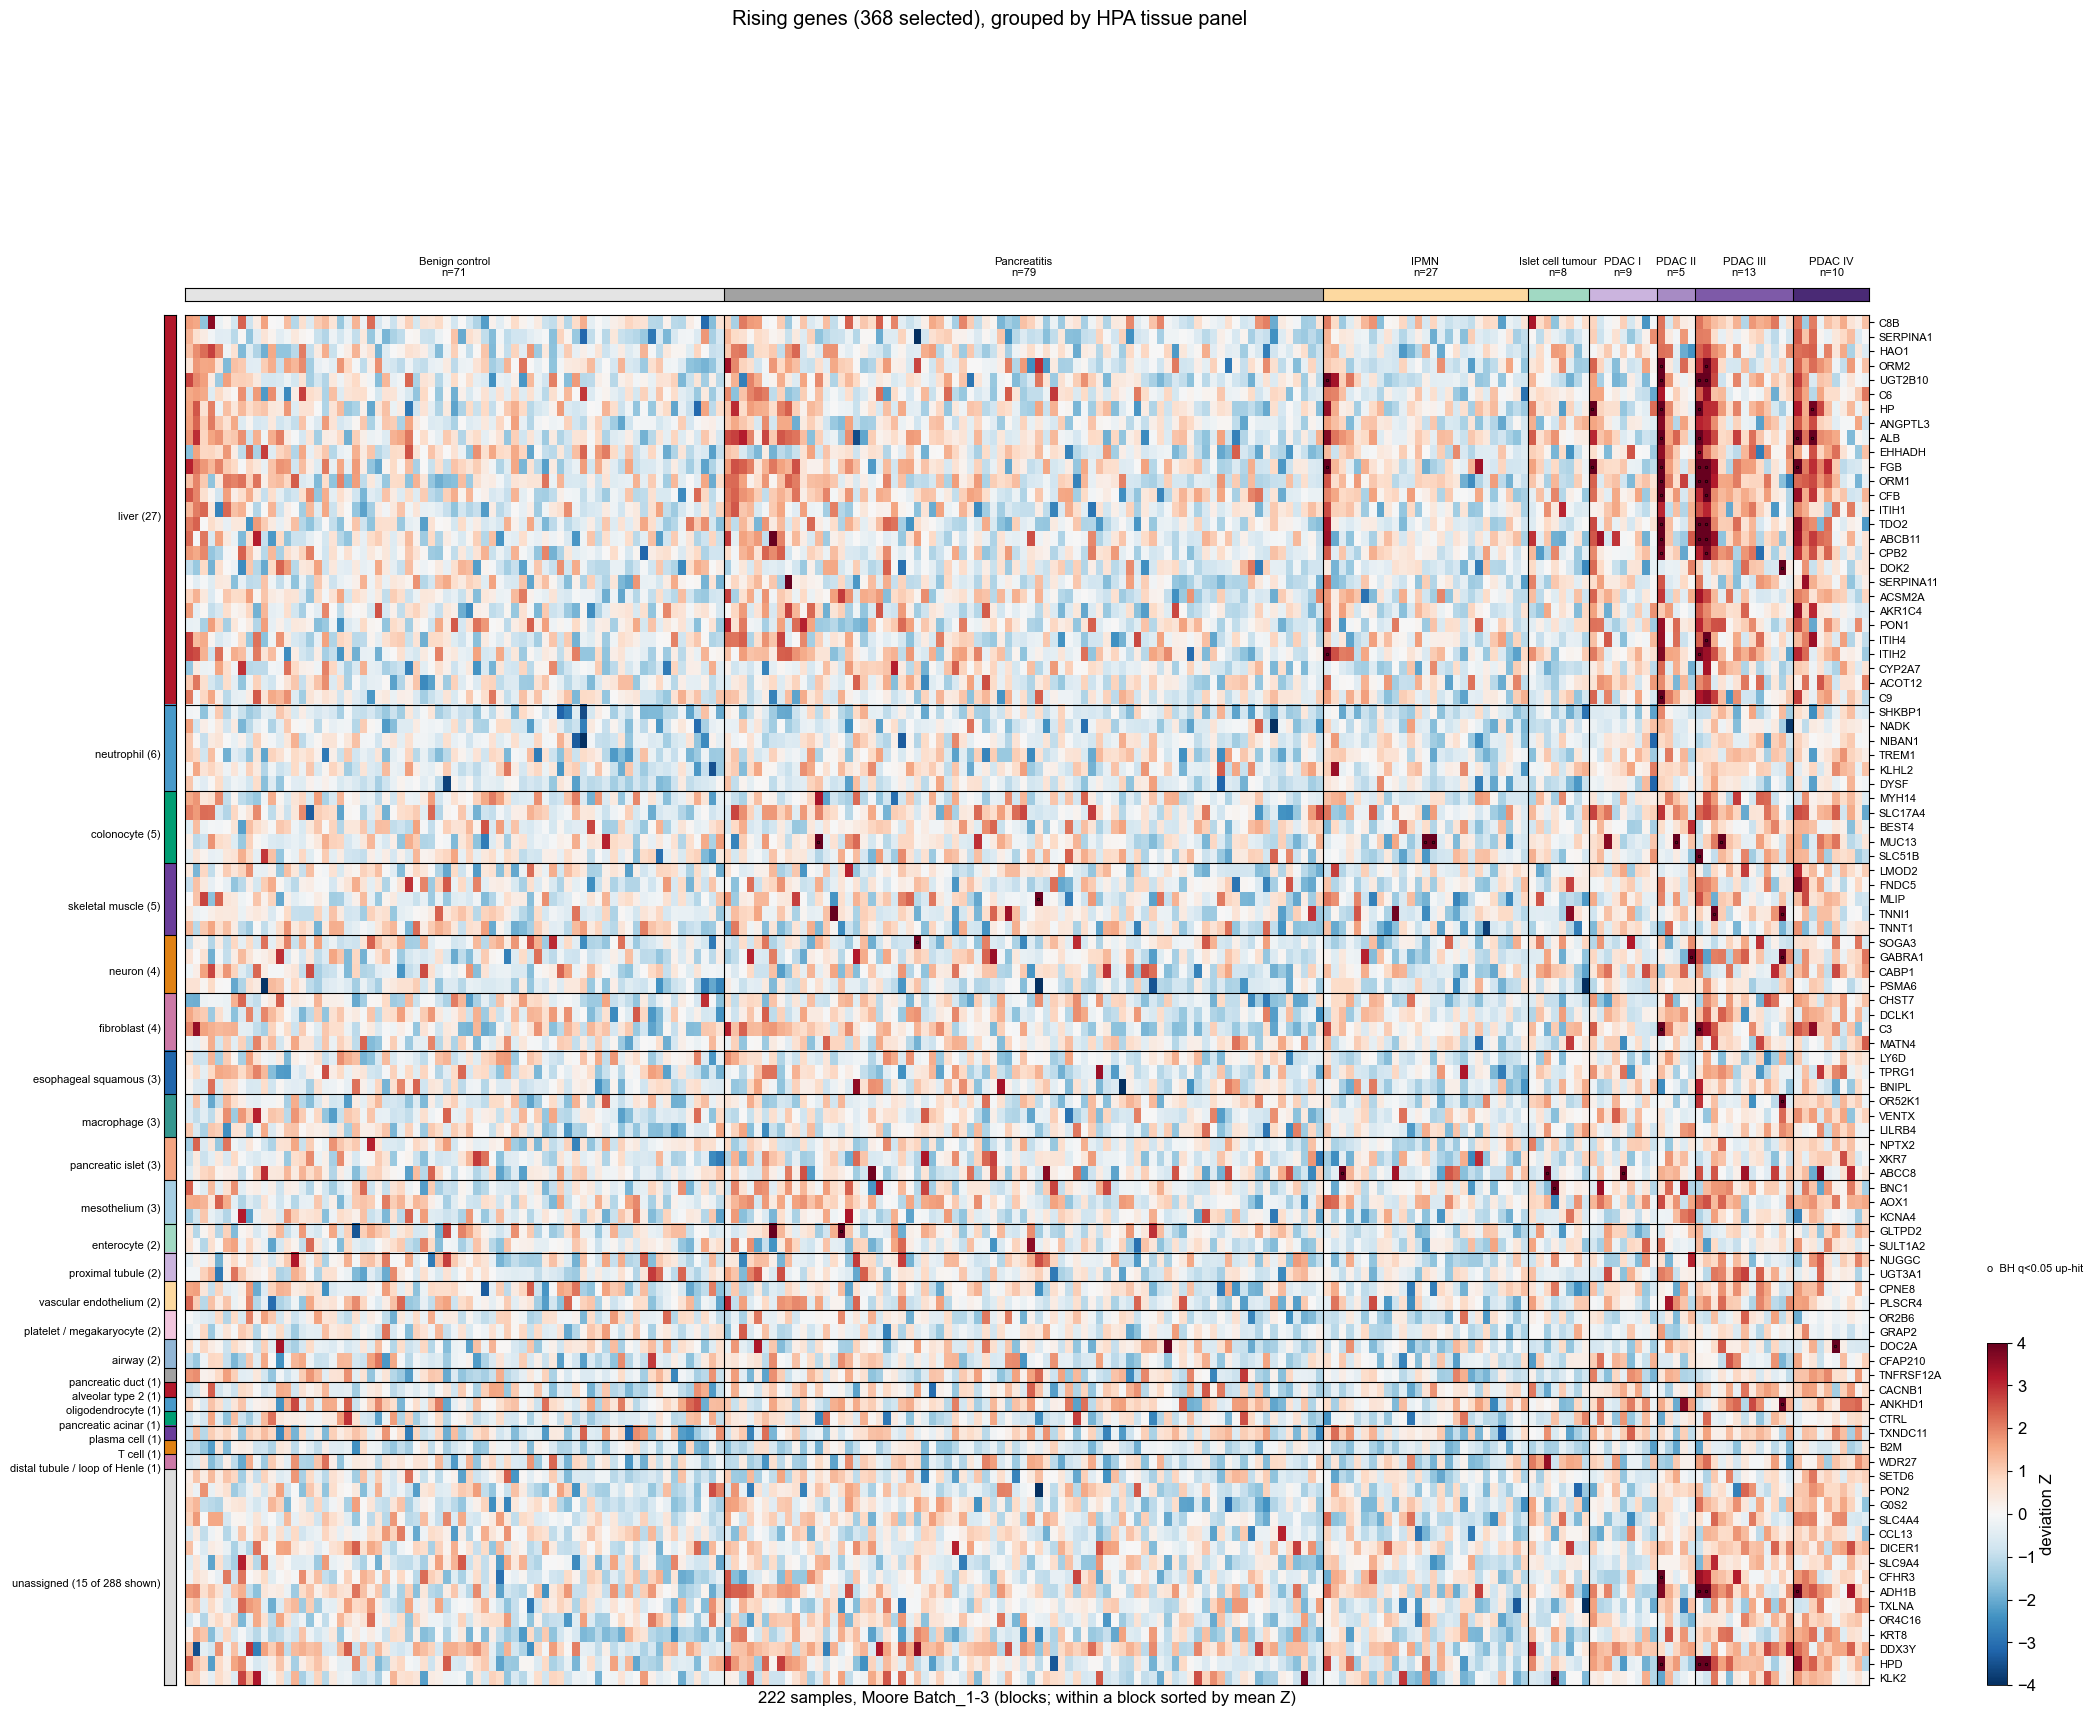

-> /project/cfRNA_NormativeModeling/MixedEffectsModeling/Notebook_p0/8_PancreaticCancerCohortsAnalysis/Figures/insample/ladder_rising_by_tissue.png


In [ ]:
# Every rising gene across every sample, rows grouped by tissue panel.
LAD_CELL_H = 0.17
Z_CLIP = 4.0

ann_L = pool[pool['panel'].notna()].copy()
una_L = pool[pool['panel'].isna()].nlargest(UNASSIGNED_TOP, 'score').assign(panel='unassigned')
order_p = list(ann_L['panel'].value_counts().index) + ['unassigned']
rows_g = pd.concat([ann_L, una_L])
rows_g['panel'] = pd.Categorical(rows_g['panel'], order_p, ordered=True)
rows_g = rows_g.sort_values(['panel', 'score'], ascending=[True, False]).reset_index(drop=True)

gcol = pd.Index(genes).get_indexer(rows_g['ens'])
ZS, HS = Z_L[:, gcol].T, HIT_L[:, gcol].T
ord_s = np.lexsort((-ZS.mean(axis=0), blk_L))
ZS, HS, bks = ZS[:, ord_s], HS[:, ord_s], blk_L[ord_s]
bnd_c = np.where(np.diff(bks))[0] + 1
grp = rows_g['panel'].cat.codes.values
bnd_r = np.where(np.diff(grp))[0] + 1
PAL = CPAL_CAT
P_C = {p: (CPAL_L['grey'] if p == 'unassigned' else PAL[i % len(PAL)]) for i, p in enumerate(order_p)}
BLK_C8 = BLK_RAMP8

H = LAD_CELL_H * len(rows_g) + 2.0
with plt.rc_context(FSP):
    fig, axes = plt.subplots(2, 2, figsize=(22, H), sharex='col',
                             gridspec_kw=dict(height_ratios=[0.18, H - 0.18], width_ratios=[0.1, 13.9],
                                              hspace=0.02, wspace=0.01))
    axes[0, 0].axis('off')
    bar, strip, ax = axes[0, 1], axes[1, 0], axes[1, 1]
    bar.imshow(bks[None, :], aspect='auto', interpolation='nearest',
               cmap=mcolors.ListedColormap(BLK_C8), vmin=-0.5, vmax=7.5)
    bar.set_yticks([])
    for i, (lo, hi) in enumerate(zip(np.r_[0, bnd_c], np.r_[bnd_c, len(bks)])):
        bar.text((lo + hi) / 2 - 0.5, -1.2, f'{BLK_LAB[i]}\nn={hi - lo}', ha='center', va='bottom',
                 fontsize=FS_ANNOT_SM, linespacing=1.1)
    strip.imshow(grp[:, None], aspect='auto', interpolation='nearest',
                 cmap=mcolors.ListedColormap([P_C[p] for p in order_p]), vmin=-0.5, vmax=len(order_p) - 0.5)
    strip.set_xticks([])
    strip.set_yticks([])
    n_una = int(pool['panel'].isna().sum())
    for lo, hi in zip(np.r_[0, bnd_r], np.r_[bnd_r, len(grp)]):
        p = order_p[grp[lo]]
        lab = f'{p} ({hi - lo} of {n_una} shown)' if p == 'unassigned' else f'{p} ({hi - lo})'
        strip.text(-0.8, (lo + hi) / 2, lab, ha='right', va='center', fontsize=FS_ANNOT_SM)
    im = ax.imshow(ZS, aspect='auto', interpolation='nearest', cmap=DIV_CMAP, vmin=-Z_CLIP, vmax=Z_CLIP)
    yy, xx = np.where(HS)
    ax.plot(xx, yy, 'o', ms=1.8, mfc='none', mec='black', mew=0.5, ls='none')
    ax.set_yticks(range(len(rows_g)))
    ax.set_yticklabels(rows_g['symbol'], fontsize=FS_ANNOT_SM)
    ax.yaxis.tick_right()
    ax.set_xticks([])
    ax.set_xlabel(f'{len(bks)} samples, Moore Batch_1-3 (blocks; within a block sorted by mean Z)')
    for a in (bar, ax):
        for b in bnd_c:
            a.axvline(b - 0.5, color='black', lw=0.8)
    for a in (strip, ax):
        for b in bnd_r:
            a.axhline(b - 0.5, color='black', lw=0.8)
    for a in (bar, strip, ax):
        for sp in a.spines.values():
            sp.set_visible(True)
            sp.set_linewidth(0.8)
    cax = ax.inset_axes([1.07, 0.0, 0.012, 0.25])
    cb = fig.colorbar(im, cax=cax)
    cb.set_label('deviation Z', labelpad=3)
    cb.outline.set_linewidth(0.6)
    ax.text(1.07, 0.30, 'o  BH q<0.05 up-hit', transform=ax.transAxes, va='bottom', ha='left',
            fontsize=FS_ANNOT_SM)
    fig.suptitle(f'Rising genes ({len(pool)} selected), grouped by HPA tissue panel', y=1.0 + 0.6 / H)
    fig.savefig(FIG / 'ladder_rising_by_tissue.png', dpi=250, bbox_inches='tight')
    plt.show()
print(f"-> {FIG / 'ladder_rising_by_tissue.png'}")

In [ ]:
# Are the rising genes without a panel genuinely non-specific, or only missing from these 30 panels?
# HPA assigns every gene a tissue-level and a single-cell-level specificity class independently of them.
SPEC_ORDER = ['Tissue enriched', 'Group enriched', 'Tissue enhanced', 'Low tissue specificity',
              'Not detected']
spec_L = pd.read_csv(config.HPA_ATLAS_ZIP, sep='\t',
                     usecols=['Ensembl', 'RNA tissue specificity', 'RNA single cell type specificity'])
spec_L.columns = ['ens', 't_cat', 's_cat']
spec_L = spec_L.drop_duplicates('ens').set_index('ens')
for col in ('t_cat', 's_cat'):
    lad[col] = base_all.map(spec_L[col]).values

sub_L = lad[lad['pool'].values]
grp_lab = np.where(sub_L['panel'].notna(), 'in a panel', 'unassigned')
tab_L = (pd.crosstab(grp_lab, sub_L['t_cat'])
         .reindex(columns=[c for c in SPEC_ORDER if c in set(sub_L['t_cat'].dropna())], fill_value=0))
tab_L['no HPA record'] = [int(sub_L.loc[grp_lab == g, 't_cat'].isna().sum()) for g in tab_L.index]
bg = lad['t_cat'].value_counts(dropna=False)

una2 = sub_L[sub_L['panel'].isna()]
share = lambda s, n: f'{s}/{n} ({s / n:.0%})'
print(f'rising genes without a panel: {len(una2)} of {len(sub_L)}')
print(f"  HPA 'Low tissue specificity': "
      f"{share(int((una2['t_cat'] == 'Low tissue specificity').sum()), len(una2))}")
print(f'  tissue enriched/enhanced but outside these {len(PANELS_L)} panels: '
      f"{share(int(una2['t_cat'].isin(['Tissue enriched', 'Group enriched', 'Tissue enhanced']).sum()), len(una2))}")
print(f"  no HPA record: {share(int(una2['t_cat'].isna().sum()), len(una2))}")
print('\nHPA tissue specificity class, rising genes -- transcriptome share in brackets')
pct = tab_L.div(tab_L.sum(axis=1), axis=0)
show = pct.copy()
for c_ in show.columns:
    b = (bg.isna().sum() if c_ == 'no HPA record' else bg.get(c_, 0)) / len(lad)
    show[c_] = [f'{v:.0%} [{b:.0%}]' for v in pct[c_]]
display(show)
tab_L.to_csv(LAD_DIR / 'unassigned_specificity.csv')
print(f"-> {LAD_DIR / 'unassigned_specificity.csv'}")

rising genes without a panel: 288 of 368
  HPA 'Low tissue specificity': 134/288 (47%)
  tissue enriched/enhanced but outside these 31 panels: 132/288 (46%)
  no HPA record: 7/288 (2%)

HPA tissue specificity class, rising genes -- transcriptome share in brackets


t_cat,Tissue enriched,Group enriched,Tissue enhanced,Low tissue specificity,Not detected,no HPA record
row_0,,,,,,
in a panel,40% [15%],25% [7%],20% [31%],12% [41%],2% [5%],0% [0%]
unassigned,13% [15%],5% [7%],28% [31%],47% [41%],5% [5%],2% [0%]


-> /project/cfRNA_NormativeModeling/MixedEffectsModeling/Notebook_p0/8_PancreaticCancerCohortsAnalysis/insample/severity_ladder/unassigned_specificity.csv


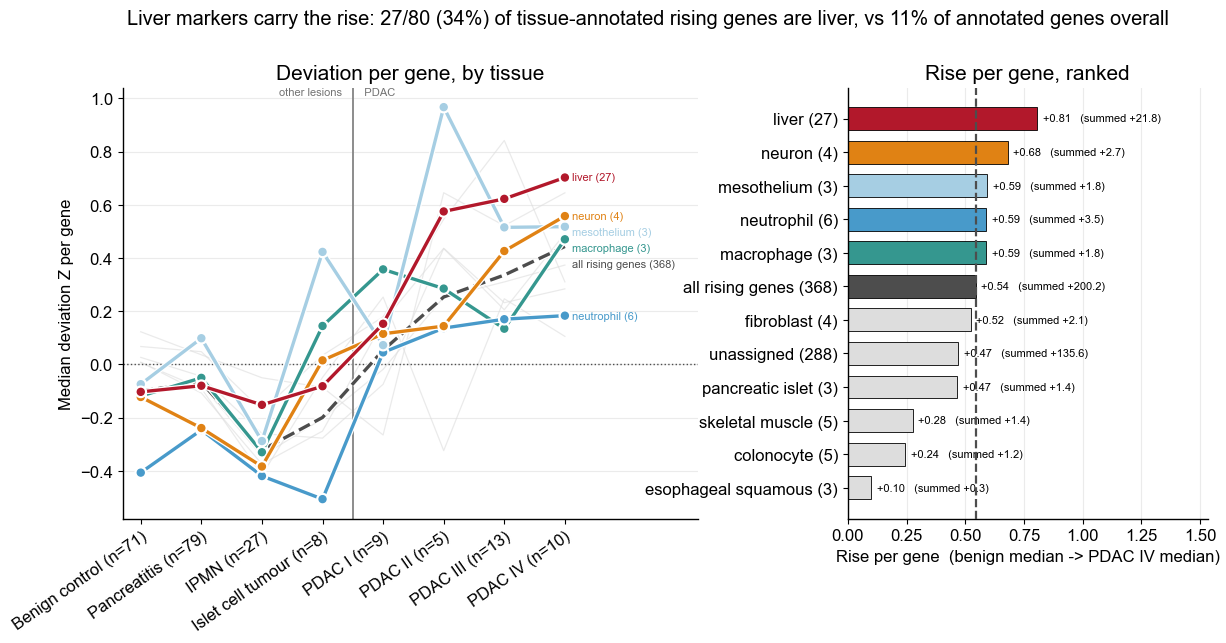

,panel,n_genes,rise,rise_sum,step,rho_neo,rho_stage,median_benign,median_pdac4
0,liver,27,0.806,21.761999,0.507,0.591,0.264,-0.103,0.703
1,neuron,4,0.680,2.721000,0.596,0.535,0.228,-0.123,0.558
2,mesothelium,3,0.592,1.777000,0.563,0.486,0.076,-0.075,0.518
3,neutrophil,6,0.590,3.542000,0.506,0.372,0.173,-0.407,0.183
4,macrophage,3,0.590,1.769000,0.464,0.415,0.230,-0.119,0.470
5,all rising genes (368),368,0.544,200.195007,0.410,0.825,0.609,-0.101,0.443
6,fibroblast,4,0.522,2.090000,0.476,0.433,0.353,0.122,0.645
7,unassigned,288,0.471,135.645996,0.377,0.831,0.644,-0.098,0.373
8,pancreatic islet,3,0.466,1.397000,0.389,0.437,0.309,0.026,0.492
9,skeletal muscle,5,0.275,1.377000,0.339,0.596,0.183,0.008,0.284


-> /project/cfRNA_NormativeModeling/MixedEffectsModeling/Notebook_p0/8_PancreaticCancerCohortsAnalysis/Figures/insample/ladder_tissue_trend.png


In [ ]:
# Each tissue against the whole selected set. Per-gene mean Z is the fair unit -- the liver panel
# holds the most rising genes, so a raw Z sum would favour it by size alone.
MIN_GENES_T = 3
ALL_LAB = f'all rising genes ({len(pool)})'
tis = [p for p, n in pool['panel'].value_counts().items() if n >= MIN_GENES_T]
col_of = lambda g: pd.Index(genes).get_indexer(g['ens'])
Zmean = {p: Z_L[:, col_of(pool[pool['panel'] == p])].mean(1) for p in tis}
Zmean[ALL_LAB] = Z_L[:, col_of(pool)].mean(1)
Zmean['unassigned'] = Z_L[:, col_of(pool[pool['panel'].isna()])].mean(1)

rows_t = []
for p, v_ in Zmean.items():
    n = len(pool) if p == ALL_LAB else int(pool['panel'].isna().sum()) if p == 'unassigned' \
        else int((pool['panel'] == p).sum())
    base = np.median(v_[blk_L == 0])
    rows_t.append(dict(panel=p, n_genes=n, rise=np.median(v_[blk_L == 7]) - base,
                       rise_sum=(np.median(v_[blk_L == 7]) - base) * n,
                       step=np.median(v_[blk_L >= 4]) - np.median(v_[blk_L < 4]),
                       rho_neo=spearmanr(rank_L[neo_L], v_[neo_L]).statistic,
                       rho_stage=spearmanr(ts_L[is_pdac], v_[is_pdac]).statistic,
                       median_benign=base, median_pdac4=np.median(v_[blk_L == 7])))
trend_t = pd.DataFrame(rows_t).sort_values('rise', ascending=False).reset_index(drop=True)
trend_t.to_csv(LAD_DIR / 'tissue_trend.csv', index=False)

n_ann_pool = int(pool['panel'].notna().sum())
n_liver_pool = int((pool['panel'] == 'liver').sum())
n_ann_all = int(lad['panel'].notna().sum())
n_liver_all = int((lad['panel'] == 'liver').sum())
ref_rise = float(trend_t.loc[trend_t['panel'] == ALL_LAB, 'rise'].iloc[0])

# a white halo under each highlighted line keeps it readable where tissues cross
HALO = [pe.Stroke(linewidth=4.2, foreground='white'), pe.Normal()]
HL_LAST = 'macrophage'   # highlight the ranked run from the top tissue down to this one
REST_C, ALL_C = CPAL_L['grey'], CPAL['dgrey']
rank_t = [p for p in trend_t['panel'] if p not in (ALL_LAB, 'unassigned')]
hl_t = rank_t[:rank_t.index(HL_LAST) + 1] if HL_LAST in rank_t else rank_t
# same tissue palette as the heatmap strip above, so a tissue keeps its colour across both figures
panel_c = lambda p: ALL_C if p == ALL_LAB else P_C.get(p, REST_C) if p in hl_t else REST_C

with plt.rc_context(FSP):
    fig, (axl, axr) = plt.subplots(1, 2, figsize=(14, 5.6), gridspec_kw=dict(width_ratios=[1.6, 1], wspace=0.32))
    # drawn worst-ranked first so the top tissue sits on top of every crossing line
    ends = []
    for p in trend_t['panel'][::-1]:
        v_ = Zmean[p]
        med_ = [np.median(v_[blk_L == b]) for b in range(8)]
        if p == ALL_LAB:
            axl.plot(range(8), med_, lw=2.4, ls='--', color=ALL_C, zorder=20, path_effects=HALO)
            ends.append([med_[7], ALL_LAB, ALL_C])
        elif p in hl_t:
            k = hl_t.index(p)
            axl.plot(range(8), med_, lw=2.4, marker='o', ms=5, color=panel_c(p), zorder=30 - k,
                     solid_capstyle='round', path_effects=HALO)
            ends.append([med_[7], f"{p} ({int(trend_t.loc[trend_t['panel'] == p, 'n_genes'].iloc[0])})", panel_c(p)])
        else:
            axl.plot(range(8), med_, lw=0.9, color=REST_C, zorder=1, alpha=0.6)
    gap = 0.115 * (max(e[0] for e in ends) - min(e[0] for e in ends) + 1e-9)
    ends.sort(key=lambda e: -e[0])
    for i in range(1, len(ends)):
        ends[i][0] = min(ends[i][0], ends[i - 1][0] - gap)
    for y_lab, name, c_ in ends:
        axl.annotate(name, (7.12, y_lab), va='center', ha='left', fontsize=FS_ANNOT_SM, color=c_)
    axl.axhline(0, color='0.3', lw=1.0, ls=':')
    axl.axvline(3.5, color='0.55', lw=1.4)
    axl.text(3.42, axl.get_ylim()[1], 'other lesions  ', ha='right', va='top', fontsize=FS_ANNOT_SM, color='0.45')
    axl.text(3.58, axl.get_ylim()[1], '  PDAC', ha='left', va='top', fontsize=FS_ANNOT_SM, color='0.45')
    axl.set_xticks(range(8))
    axl.set_xticklabels([f'{l} (n={int((blk_L == b).sum())})' for b, l in enumerate(BLK_LAB)],
                        rotation=35, ha='right', rotation_mode='anchor')
    axl.set_ylabel('Median deviation Z per gene')
    axl.set_xlim(-0.3, 9.2)
    axl.grid(axis='y', color='0.92', lw=0.8)
    axl.set_axisbelow(True)
    axl.set_title('Deviation per gene, by tissue')

    y = np.arange(len(trend_t))[::-1]
    cols = [panel_c(p) for p in trend_t['panel']]
    axr.barh(y, trend_t['rise'], color=cols, edgecolor='black', lw=0.6, height=0.68)
    axr.axvline(ref_rise, color=ALL_C, lw=1.6, ls='--', zorder=4)
    for i, r in trend_t.iterrows():
        axr.text(r['rise'] + trend_t['rise'].max() * 0.03, y[i],
                 f"{r['rise']:+.2f}   (summed {r['rise_sum']:+.1f})", va='center', ha='left',
                 fontsize=FS_ANNOT_SM)
    axr.set_yticks(y)
    axr.set_yticklabels([p if p == ALL_LAB else f"{p} ({n})"
                         for p, n in zip(trend_t['panel'], trend_t['n_genes'])])
    axr.set_xlabel('Rise per gene  (benign median -> PDAC IV median)')
    axr.set_xlim(0, trend_t['rise'].max() * 1.9)
    axr.grid(axis='x', color='0.92', lw=0.8)
    axr.set_axisbelow(True)
    axr.set_title('Rise per gene, ranked')
    fig.suptitle(f'Liver markers carry the rise: {n_liver_pool}/{n_ann_pool} '
                 f'({n_liver_pool / n_ann_pool:.0%}) of tissue-annotated rising genes are liver, '
                 f'vs {n_liver_all / n_ann_all:.0%} of annotated genes overall', y=1.02)
    fig.savefig(FIG / 'ladder_tissue_trend.png', dpi=300, bbox_inches='tight')
    plt.show()
display(trend_t.round(3))
print(f"-> {FIG / 'ladder_tissue_trend.png'}")

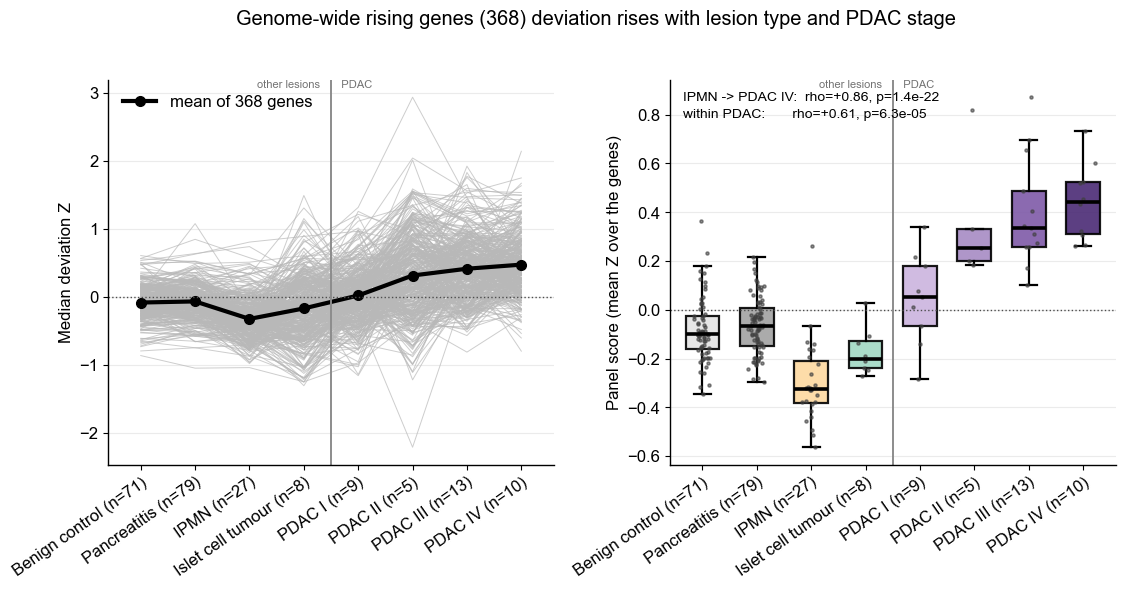

Genome-wide rising genes (368): 368 genes, IPMN->PDAC IV rho +0.864 (p 1.4e-22), within PDAC rho +0.609 (p 6.3e-05)  -> /project/cfRNA_NormativeModeling/MixedEffectsModeling/Notebook_p0/8_PancreaticCancerCohortsAnalysis/Figures/insample/ladder_trend_all.png


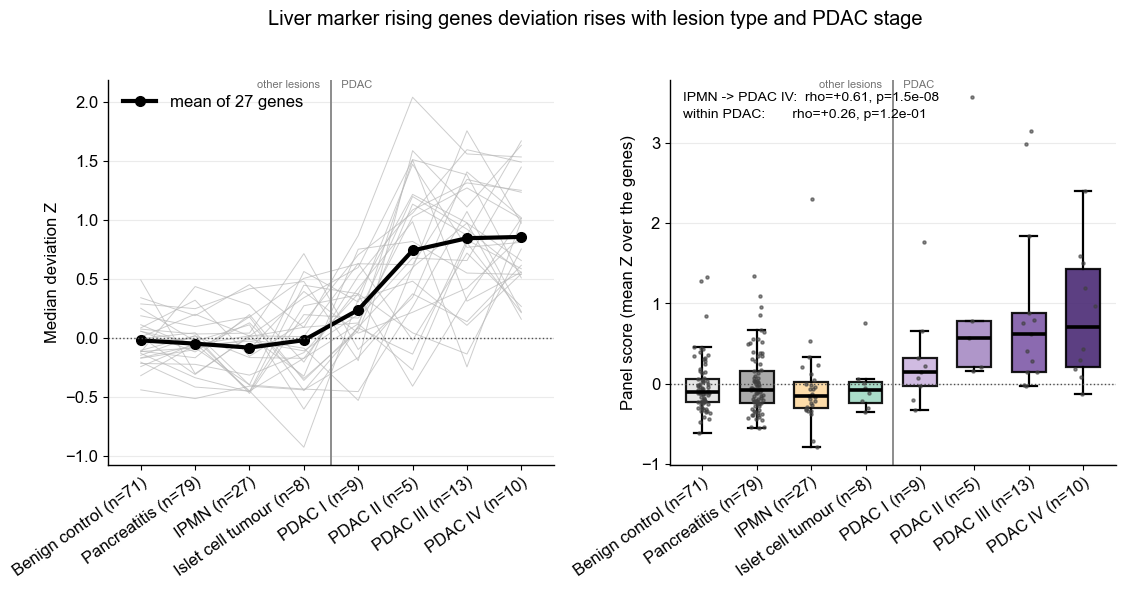

Liver marker rising genes: 27 genes, IPMN->PDAC IV rho +0.608 (p 1.5e-08), within PDAC rho +0.264 (p 1.2e-01)  -> /project/cfRNA_NormativeModeling/MixedEffectsModeling/Notebook_p0/8_PancreaticCancerCohortsAnalysis/Figures/insample/ladder_trend_liver.png


In [ ]:
# Per-gene trajectories and the per-sample panel score, for the whole set and for liver alone.
def trend_fig(gdf, label, fname):
    cols = pd.Index(genes).get_indexer(gdf['ens'])
    med_ = np.vstack([np.median(Z_L[blk_L == b][:, cols], axis=0) for b in range(8)])
    sc = Z_L[:, cols].mean(axis=1)
    r_all = spearmanr(blk_L[blk_L >= 2], sc[blk_L >= 2])
    r_pd = spearmanr(ts_L[is_pdac], sc[is_pdac])
    xt = [f'{l} (n={int((blk_L == b).sum())})' for b, l in enumerate(BLK_LAB)]

    with plt.rc_context(FSP):
        fig, (axl, axr) = plt.subplots(1, 2, figsize=(13, 5.0), gridspec_kw=dict(wspace=0.26))
        for j in range(med_.shape[1]):
            axl.plot(range(8), med_[:, j], color='0.72', lw=0.7, alpha=0.7)
        axl.plot(range(8), med_.mean(axis=1), color='black', lw=3.0, marker='o', ms=7,
                 label=f'mean of {med_.shape[1]} genes')
        axl.axhline(0, color='0.3', lw=1.0, ls=':')
        axl.set_ylabel('Median deviation Z')
        axl.legend(frameon=False, loc='upper left')

        bp = axr.boxplot([sc[blk_L == b] for b in range(8)], positions=range(8), widths=0.62,
                         patch_artist=True, showfliers=False, medianprops=dict(color='black', lw=2.6),
                         whiskerprops=dict(lw=1.6), capprops=dict(lw=1.6),
                         boxprops=dict(lw=1.6, edgecolor='black'))
        for b, box in enumerate(bp['boxes']):
            box.set_facecolor(BLK_C8[b])
            box.set_alpha(0.9)
        rngp = np.random.default_rng(SEED)
        for b in range(8):
            vv = sc[blk_L == b]
            axr.plot(b + rngp.normal(0, 0.07, len(vv)), vv, '.', ms=4.5, color='0.25', alpha=0.6)
        axr.axhline(0, color='0.3', lw=1.0, ls=':')
        axr.set_ylabel('Panel score (mean Z over the genes)')
        axr.text(0.03, 0.97, f'IPMN -> PDAC IV:  rho={r_all.statistic:+.2f}, p={r_all.pvalue:.1e}\n'
                             f'within PDAC:       rho={r_pd.statistic:+.2f}, p={r_pd.pvalue:.1e}',
                 transform=axr.transAxes, va='top', ha='left', fontsize=FS_ANNOT_LG - 2, linespacing=1.5)
        for a in (axl, axr):
            a.axvline(3.5, color='0.55', lw=1.4)
            a.text(3.42, a.get_ylim()[1], 'other lesions  ', ha='right', va='top',
                   fontsize=FS_ANNOT_SM, color='0.45')
            a.text(3.58, a.get_ylim()[1], '  PDAC', ha='left', va='top',
                   fontsize=FS_ANNOT_SM, color='0.45')
            a.set_xticks(range(8))
            a.set_xticklabels(xt, rotation=35, ha='right', rotation_mode='anchor')
            a.set_xlim(-0.6, 7.6)
            a.grid(axis='y', color='0.92', lw=0.8)
            a.set_axisbelow(True)
        fig.suptitle(f'{label} deviation rises with lesion type and PDAC stage', y=1.02)
        fig.savefig(FIG / fname, dpi=300, bbox_inches='tight')
        plt.show()
    print(f'{label}: {len(gdf)} genes, IPMN->PDAC IV rho {r_all.statistic:+.3f} (p {r_all.pvalue:.1e}), '
          f'within PDAC rho {r_pd.statistic:+.3f} (p {r_pd.pvalue:.1e})  -> {FIG / fname}')

trend_fig(pool, f'Genome-wide rising genes ({len(pool)})', 'ladder_trend_all.png')
trend_fig(pool[pool['panel'] == 'liver'], 'Liver marker rising genes', 'ladder_trend_liver.png')

### Is the liver signal just liver metastasis, or just CA19-9?

The liver panel carries the largest share of the rising genes, so the obvious objection is that it
restates something already measured in the clinic. Two tests inside the PDAC patients, both on the
per-sample liver panel score (sum of Z over the liver genes):

- **liver metastasis** as a group split (Mann-Whitney), using the `Met_Site` field,
- **CA19-9** as a rank correlation (Spearman), on the patients who have a value.

Both are negative, which is the point: the axis is weak but it is not a restatement of either.
Note the asymmetry of the split -- liver metastasis is recorded only in stage IV, so the contrast is
7 against 30 and cannot exclude a modest effect.


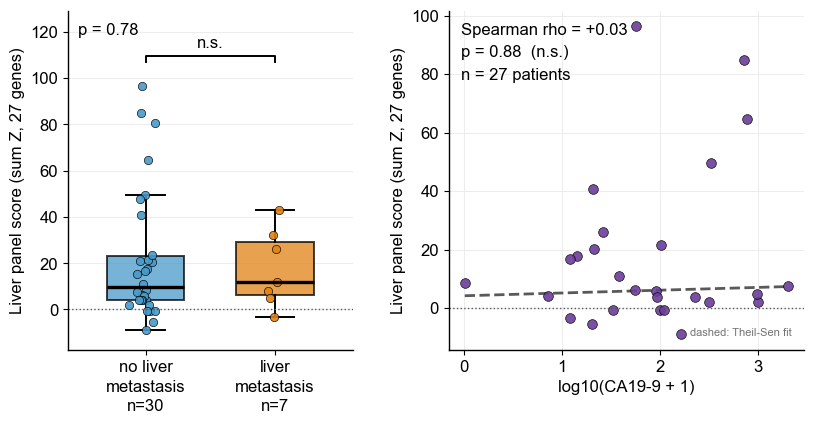

liver met 7 vs 30: MWU p = 0.776
CA19-9 within PDAC: rho +0.031, p = 0.877, n = 27
-> /project/cfRNA_NormativeModeling/MixedEffectsModeling/Notebook_p0/8_PancreaticCancerCohortsAnalysis/Figures/insample/ladder_liver_independence.png  |  /project/cfRNA_NormativeModeling/MixedEffectsModeling/Notebook_p0/8_PancreaticCancerCohortsAnalysis/insample/severity_ladder/liver_independence.csv


In [ ]:
# Does the liver panel score restate liver metastasis or CA19-9? Two simple tests inside PDAC.
from scipy.stats import mannwhitneyu, theilslopes

C_MET3, C_NOMET2, C_CA = CPAL['orange'], CPAL['blue'], CPAL['purple']
with h5py.File(config.H5AD_PATH, 'r') as h:
    idx_o = pd.Index(dec(h['obs/_index'][()]))
    def obs_col(n):
        o = h[f'obs/{n}']
        return pd.Series(pd.Categorical.from_codes(o['codes'][()], dec(o['categories'][()])).astype(str)
                         if isinstance(o, h5py.Group) else np.asarray(o[()]), index=idx_o)
    met_all, ca_all = obs_col('Met_Site'), obs_col('CA19_9')

liver_met = np.array(['liver' in m for m in
                      pd.Series(names_L).map(met_all).fillna('not recorded').str.lower().values])
lca = np.log10(np.clip(pd.to_numeric(pd.Series(names_L).map(ca_all), errors='coerce').values, 0, None) + 1)
ok_ca = np.isfinite(lca)
liver_cols = pd.Index(genes).get_indexer(pool.loc[pool['panel'] == 'liver', 'ens'])
v_liv = Z_L[:, liver_cols].sum(1)

g_no, g_met = is_pdac & ~liver_met, is_pdac & liver_met
u_met = mannwhitneyu(v_liv[g_met], v_liv[g_no])
m_ca = ok_ca & is_pdac
r_ca = spearmanr(lca[m_ca], v_liv[m_ca])
stars = lambda p: 'n.s.' if p >= 0.05 else ('*' if p >= 0.01 else ('**' if p >= 0.001 else '***'))

pd.DataFrame([dict(test='liver met vs none (Mann-Whitney)', n1=int(g_met.sum()), n2=int(g_no.sum()),
                   stat=u_met.statistic, p=u_met.pvalue,
                   median1=np.median(v_liv[g_met]), median2=np.median(v_liv[g_no])),
              dict(test='liver score vs log10 CA19-9 (Spearman)', n1=int(m_ca.sum()), n2=np.nan,
                   stat=r_ca.statistic, p=r_ca.pvalue, median1=np.nan, median2=np.nan)]
             ).to_csv(LAD_DIR / 'liver_independence.csv', index=False)

YL = f'Liver panel score (sum Z, {len(liver_cols)} genes)'
GRP = [('no liver\nmetastasis', g_no, C_NOMET2), ('liver\nmetastasis', g_met, C_MET3)]
rngs = np.random.default_rng(0)
with plt.rc_context(FSP):
    fig, (axm, axc) = plt.subplots(1, 2, figsize=(9.5, 4.4),
                                   gridspec_kw=dict(width_ratios=[1, 1.25], wspace=0.30))

    bx = axm.boxplot([v_liv[m] for _, m, _ in GRP], positions=[0, 1], widths=0.6,
                     patch_artist=True, showfliers=False, medianprops=dict(color='black', lw=2.4),
                     whiskerprops=dict(lw=1.4), capprops=dict(lw=1.4))
    for b, (_, _, c) in zip(bx['boxes'], GRP):
        b.set(facecolor=c, alpha=0.75, edgecolor='black', lw=1.4)
    for i, (lab, m, c) in enumerate(GRP):
        vv = v_liv[m]
        axm.plot(i + rngs.normal(0, 0.055, len(vv)), vv, 'o', ms=6, color=c, mec='black',
                 mew=0.5, alpha=0.9)
    axm.axhline(0, color='0.35', lw=1.0, ls=':')
    top, bot = v_liv[is_pdac].max(), v_liv[is_pdac].min()
    span = top - bot
    ybar = top + 0.10 * span
    axm.plot([0, 0, 1, 1], [ybar, ybar + 0.025 * span, ybar + 0.025 * span, ybar], color='black', lw=1.4)
    axm.text(0.5, ybar + 0.045 * span, stars(u_met.pvalue), ha='center', va='bottom',
             fontsize=FS_ANNOT_LG)
    axm.set_ylim(bot - 0.08 * span, ybar + 0.21 * span)
    axm.set_xlim(-0.6, 1.6)
    axm.set_xticks([0, 1])
    axm.set_xticklabels([f'{l}\nn={int(m.sum())}' for l, m, _ in GRP], linespacing=1.4)
    axm.set_ylabel(YL)
    axm.text(0.035, 0.965, f'p = {u_met.pvalue:.2f}', transform=axm.transAxes,
             ha='left', va='top', fontsize=FS_ANNOT_LG)

    axc.plot(lca[m_ca], v_liv[m_ca], 'o', ms=7, color=C_CA, mec='black', mew=0.5, alpha=0.9)
    sl, ic, _, _ = theilslopes(v_liv[m_ca], lca[m_ca])
    xs = np.linspace(lca[m_ca].min(), lca[m_ca].max(), 50)
    axc.plot(xs, sl * xs + ic, color='0.35', lw=2.0, ls='--', zorder=1)
    axc.axhline(0, color='0.35', lw=1.0, ls=':')
    axc.text(0.035, 0.965, f'Spearman rho = {r_ca.statistic:+.2f}\np = {r_ca.pvalue:.2f}  '
             f'({stars(r_ca.pvalue)})\nn = {int(m_ca.sum())} patients', transform=axc.transAxes,
             ha='left', va='top', fontsize=FS_ANNOT_LG, linespacing=1.6)
    axc.text(0.965, 0.035, 'dashed: Theil-Sen fit', transform=axc.transAxes, ha='right', va='bottom',
             fontsize=FS_ANNOT_SM, color='0.45')
    axc.set_xlabel('log10(CA19-9 + 1)')
    axc.set_ylabel(YL)

    for a in (axm, axc):
        a.grid(axis='y', color='0.93', lw=0.8)
        a.set_axisbelow(True)
    axc.grid(axis='x', color='0.93', lw=0.8)
    fig.savefig(FIG / 'ladder_liver_independence.png', dpi=300, bbox_inches='tight')
    plt.show()
print(f'liver met {int(g_met.sum())} vs {int(g_no.sum())}: MWU p = {u_met.pvalue:.3f}')
print(f'CA19-9 within PDAC: rho {r_ca.statistic:+.3f}, p = {r_ca.pvalue:.3f}, n = {int(m_ca.sum())}')
print(f"-> {FIG / 'ladder_liver_independence.png'}  |  {LAD_DIR / 'liver_independence.csv'}")
